In [4]:
import numpy as np

import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances

In [41]:
class Signal:
    
    ### TODO:
    ### - add Fourier scaling
    
    def __init__(self, signal, d, normalize=True, rescale=True, mask=True, radius=False):
        
        self.signal = signal.astype(np.float32)
        self.d = d  # dimension of input signal
        self.shape = signal.shape
        self.normalize = normalize  # normalize signal to sum to 1
        self.rescale = rescale  # rescale normalization to sum to signal size
        self.mask = mask
        self.radius = radius
        
        if d == 2 and len(self.shape) == 3:
            self.n, self.ny, self.nx = self.shape
        elif d == 2 and len(self.shape) == 2:
            self.n, self.ny, self.nx = 1, self.shape[0], self.shape[1]
            self.signal = signal[np.newaxis, ...]

        if d == 3 and len(self.shape) == 4:
            self.n, self.nz, self.ny, self.nx = f.shape
        elif d == 3 and len(self.shape) == 3:
            self.n, self.nz, self.ny, self.nx = 1, self.shape[0], self.shape[1], self.shape[2]
            self.signal = signal[np.newaxis, ...]
        

    def apply_mask(self):
        
        mask = utils.sphere_mask(self.ny, self.d, radius=self.radius)
        signal_mask = mask * self.signal
        
        return signal_mask


    def normalize_signal(self):
    
        if self.d == 2:
            scale = np.sum(self.signal, axis=(1,2))
            signal_norm = self.signal / scale.reshape(self.n, 1, 1)
        
        if self.d == 3:
            scale = np.sum(self.signal, axis=(1,2,3))
            signal_norm = self.signal / scale.reshape(self.n, 1, 1, 1)

        if self.rescale:
            signal_norm *= self.ny
        
        return signal_norm


    def preprocess_signals(self):
        
        if self.mask:
            self.signal = self.apply_mask()
            
        if self.normalize:
            self.signal = self.normalize_signal()
        
        return self.signal

In [42]:
### test 4 cases, 1-2D, n-2D, 1-3D, n-3D

n = 10
d = 2
L = 50

# f = np.random.normal(0, 1, (n, L, L))
f = np.random.normal(0, 1, (L, L))

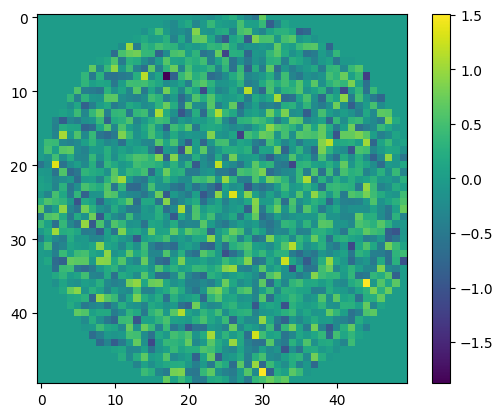

50.0


In [47]:
z = Signal(f, d=2, rescale=True).preprocess_signals()

idx = 0

plt.imshow(z[idx])
plt.colorbar()
plt.show()

print(np.sum(z[idx]))

In [44]:
n = 10
d = 3
L = 50

# f = np.random.normal(0, 1, (n, L, L, L))
f = np.random.normal(0, 1, (L, L, L))

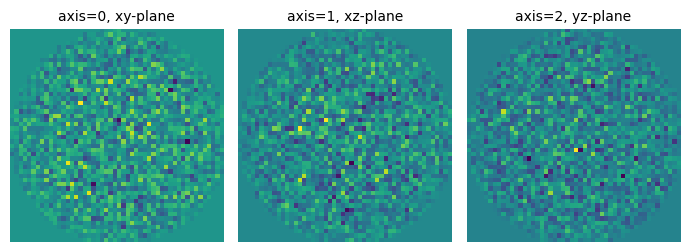

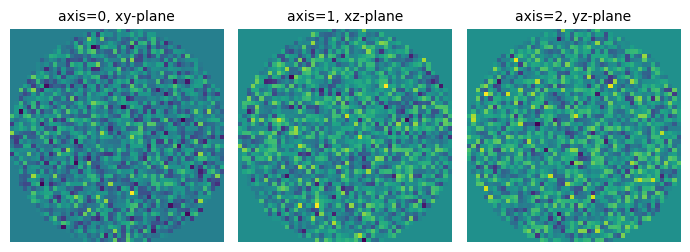

50.0


In [45]:
z = Signal(f, d=3).preprocess_signals()

idx = 0

plots.orthogonal_2D_projection_plot(z[idx])
plots.orthogonal_2D_slice_plot(z[idx])

print(np.sum(z[idx]))

In [ ]:
### test 2D

L = 65
f = np.ones((L,L))

mask = utils.sphere_mask(f)
f = f * mask

plt.imshow(f)

In [ ]:
### test 3D

L = 65
f = np.ones((L,L,L))

mask = utils.sphere_mask(f)
f = f * mask

plots.orthogonal_2D_slice_plot(f)
plots.orthogonal_2D_projection_plot(f)